# TP2 â€” Retrieval-Augmented Generation (Part 2)
## From Retriever to Answering Agent â€” Evaluation with RAGAS

**Module 2IAiasd 9.7 â€” Agentic AI Â· IMT Mines AlÃ¨s**  
**Duration:** 2 h  
**Prerequisites:** TP2 Part 1 completed â€” `chroma_db/` folder must be in the same directory as this notebook.

---

### What you will build today

```
  Part 1 (done)                   Part 2 (today)
  â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€                   â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  PDF â†’ chunks â†’ ChromaDB         ChromaDB â†’ retriever
                                       â”‚
                                       â–¼
                               Section 1: RetrievalQA chain (classic RAG)
                               Section 2: Hybrid search  (BM25 + vectors)
                               Section 3: Agentic RAG    (retrieve as @tool)
                               Section 4: RAGAS evaluation
                               Section 5: Classic RAG vs Agentic RAG
```

---

> **Important:** Run Part 1 first to generate `chroma_db/`.  
> If you skipped Part 1, set `REBUILD_INDEX = True` in Section 0 â€” the notebook will re-index automatically.

## Setup â€” Install dependencies

In [1]:
# langchain-community is pinned to 0.4.1: version 0.4.2 removed
# `langchain_community.chat_models.vertexai`, which ragas 0.4.x still imports.
# langchain-experimental 0.4.2 requires langchain-community>=0.4.2, so it is pinned too.
%pip install -q \
    langchain \
    langchain-ollama \
    "langchain-community==0.4.1" \
    langchain-chroma \
    "langchain-experimental==0.4.1" \
    pypdf \
    chromadb \
    rank-bm25 \
    ragas

print("âœ… Dependencies installed")

Note: you may need to restart the kernel to use updated packages.
âœ… Dependencies installed


## Imports

In [2]:
import textwrap
import shutil
from pathlib import Path

# LangChain â€” core
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

# LangChain â€” retrieval
from langchain_classic.retrievers import EnsembleRetriever
from langchain_community.retrievers import BM25Retriever

# LangChain â€” tools
from langchain_core.tools import tool

# Utilities
import numpy as np

print("âœ… Imports OK")

âœ… Imports OK


---
## Section 0 â€” Reload ChromaDB from Part 1

We reload the two collections built in Part 1 without re-embedding.

In [3]:
# â”€â”€ CONFIGURE THIS â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
PDF_PATH    = "my_pdf.pdf"
CHROMA_DIR  = "./chroma_db"
EMBED_MODEL = "nomic-embed-text"
LLM_MODEL   = "qwen2.5:3b"
REBUILD_INDEX = False   # set True if you skipped Part 1
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

embeddings = OllamaEmbeddings(model=EMBED_MODEL)
llm        = ChatOllama(model=LLM_MODEL, temperature=0)

print(f"âœ… Embedding model : {EMBED_MODEL}")
print(f"âœ… LLM             : {LLM_MODEL}")

âœ… Embedding model : nomic-embed-text
âœ… LLM             : qwen2.5:3b


In [4]:
def build_index_from_pdf(pdf_path: str, chroma_dir: str) -> None:
    """Re-index the PDF if chroma_db/ is missing (fallback for Part-1 skippers)."""
    from langchain_community.document_loaders import PyPDFLoader
    from langchain_text_splitters import RecursiveCharacterTextSplitter

    if Path(pdf_path).exists():
        pages = PyPDFLoader(pdf_path).load()
    else:
        # Minimal sample fallback
        SAMPLE = (
            "Chapter 1 â€” Introduction to Machine Learning. "
            "Machine learning enables computers to learn from data. "
            "Chapter 2 â€” Neural Networks. "
            "A neural network is composed of layers of neurons. "
            "Chapter 3 â€” Project Results. "
            "Our project achieved 87% accuracy using a fine-tuned BERT model. "
            "The main challenge was class imbalance, addressed with SMOTE."
        )
        pages = [Document(page_content=SAMPLE, metadata={"source": "sample", "page": 0})]

    splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)
    chunks   = splitter.split_documents(pages)

    if Path(chroma_dir).exists():
        shutil.rmtree(chroma_dir)

    Chroma.from_documents(
        documents=chunks, embedding=embeddings,
        collection_name="rapport_recursive", persist_directory=chroma_dir,
    )
    print(f"âœ… Re-indexed {len(chunks)} chunks into '{chroma_dir}'")


if REBUILD_INDEX or not Path(CHROMA_DIR).exists():
    print("âš™ï¸  chroma_db/ not found â€” rebuilding index...")
    build_index_from_pdf(PDF_PATH, CHROMA_DIR)

# Load the recursive collection (main collection used throughout Part 2)
vectorstore = Chroma(
    collection_name="rapport_recursive",
    embedding_function=embeddings,
    persist_directory=CHROMA_DIR,
)
n = vectorstore._collection.count()
print(f"âœ… Loaded 'rapport_recursive' â€” {n} vectors")

âœ… Loaded 'rapport_recursive' â€” 84 vectors


---
## Section 1 â€” Classic RAG: RetrievalQA Chain

Classic RAG = **one shot**: embed query â†’ retrieve top-k chunks â†’ prompt LLM with chunks as context â†’ answer.

```
  question
     â”‚
     â”œâ”€â”€â–º embed â”€â”€â–º ChromaDB â”€â”€â–º top-k chunks
     â”‚                                 â”‚
     â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”˜
                        â”‚
                        â–¼
               RAG prompt template
                        â”‚
                        â–¼
                  LLM (qwen2.5:3b)
                        â”‚
                        â–¼
                      answer
```

### 1.1 Build the RAG chain with LCEL

In [5]:
# â”€â”€ Retriever â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

# â”€â”€ RAG prompt â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
RAG_TEMPLATE = """\
You are an assistant that answers questions strictly based on the provided context.
If the answer is not in the context, say "I don't know â€” the document does not mention this."
Do not use any knowledge outside the context.

Context:
{context}

Question: {question}

Answer:"""

rag_prompt = ChatPromptTemplate.from_template(RAG_TEMPLATE)

# â”€â”€ Helper: format retrieved documents into a single string â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
def format_docs(docs: list[Document]) -> str:
    return "\n\n".join(
        f"[Source: page {d.metadata.get('page','?')}]\n{d.page_content}"
        for d in docs
    )

# â”€â”€ LCEL chain â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# RunnablePassthrough keeps the original question available after retrieval.
rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt
    | llm
    | StrOutputParser()
)

print("âœ… Classic RAG chain ready")

âœ… Classic RAG chain ready


### 1.2 Ask a question

In [6]:
# â”€â”€ CONFIGURE THIS â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
QUESTION = "What were the main results found in the experiment?"
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

print(f"Question: {QUESTION}")
print("â”€" * 60)

answer_classic = rag_chain.invoke(QUESTION)

print("Answer (Classic RAG):")
print(textwrap.fill(answer_classic, width=72))

Question: What were the main results found in the experiment?
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€


Failed to multipart ingest runs: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


Answer (Classic RAG):
The main results found in the experiment were a comprehensive evaluation
of modern SLMs on major Brazilian university entrance exams, a granular
analysis of model performance mapped across specific disciplines and
cognitive capabilities, an empirical assessment of the performance
penalty incurred by replacing visual questions with textual
descriptions, and a detailed cost-benefit analysis delineating the
Pareto frontier.


### 1.3 Inspect what the retriever returned

Understanding **which** chunks the LLM received is essential for debugging.

In [7]:
retrieved_docs = retriever.invoke(QUESTION)

print(f"Chunks sent to the LLM for: '{QUESTION}'")
print("â”€" * 60)
for i, doc in enumerate(retrieved_docs):
    print(f"\n[Chunk {i+1}] page={doc.metadata.get('page','?')} | {len(doc.page_content)} chars")
    print(textwrap.fill(doc.page_content[:300], width=70))

Chunks sent to the LLM for: 'What were the main results found in the experiment?'
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

[Chunk 1] page=1 | 437 chars
In summary, our main contributions are: (1) a comprehensive evaluation
of mod- ern SLMs on major Brazilian university entrance exams; (2) a
granular analysis of model performance mapped across specific
disciplines and cognitive capabilities; (3) an empir- ical assessment
of the performance penalty i

[Chunk 2] page=1 | 448 chars
ics, History, Physics, etc.) in their original Portuguese formulation,
testing logic, culture- specific knowledge, and text comprehension. To
enable automated evaluation, we re- stricted the benchmark to
multiple-choice items containing a single discrete target an- swer,
retaining the original state

[Chunk 3] page=1 | 451 chars
system. We rely on a dataset comprising quest

---
## Section 2 â€” Hybrid Search: BM25 + Vectors

Pure vector search can miss documents that share exact keywords with the query
(e.g. proper nouns, acronyms, technical terms).  
**BM25** (a keyword ranking algorithm) catches those.  
`EnsembleRetriever` merges both rankings with **Reciprocal Rank Fusion (RRF)**.

```
  question
     â”œâ”€â”€â–º BM25 (keyword)   â”€â”€â–º  ranked list A
     â”‚                                â”‚
     â”œâ”€â”€â–º ChromaDB (vector) â”€â”€â–º  ranked list B
     â”‚                                â”‚
     â””â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€ RRF merge â”€â”€â”€â”€â”€â”€â”€â”˜
                        â”‚
                        â–¼
                   top-k fused results
```

### 2.1 Build the hybrid retriever

In [8]:
# Retrieve all chunks from ChromaDB to build the BM25 index
all_docs_data = vectorstore._collection.get(include=["documents", "metadatas"])
all_chunks = [
    Document(page_content=text, metadata=meta)
    for text, meta in zip(all_docs_data["documents"], all_docs_data["metadatas"])
]
print(f"Building BM25 index on {len(all_chunks)} chunks...")

# BM25 retriever â€” keyword-based
bm25_retriever = BM25Retriever.from_documents(all_chunks, k=4)

# Vector retriever â€” semantic
vector_retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

# Ensemble: 50% BM25 + 50% vector  (weights must sum to 1)
hybrid_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, vector_retriever],
    weights=[0.5, 0.5],
)

print("âœ… Hybrid retriever ready (BM25 50% + vector 50%)")

Building BM25 index on 84 chunks...
âœ… Hybrid retriever ready (BM25 50% + vector 50%)


### 2.2 Compare pure-vector vs hybrid retrieval

In [9]:
def show_top_chunks(retriever, query: str, label: str, k: int = 3) -> list[Document]:
    docs = retriever.invoke(query)[:k]
    print(f"\n{'â”€'*60}")
    print(f"  {label}  |  query: '{query}'")
    print(f"{'â”€'*60}")
    for i, d in enumerate(docs):
        print(f"  [{i+1}] page={d.metadata.get('page','?')}  {d.page_content[:120].strip()}...")
    return docs


HYBRID_QUERY = "What is gemma-4-31B-it FUVEST cost-benefit"  # keyword-heavy query

docs_vector = show_top_chunks(vector_retriever, HYBRID_QUERY, "VECTOR")
docs_hybrid = show_top_chunks(hybrid_retriever, HYBRID_QUERY, "HYBRID")

print()
print("Observation: hybrid retrieval often surfaces keyword-exact matches")
print("that pure vector search would rank lower.")


â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  VECTOR  |  query: 'What is gemma-4-31B-it FUVEST cost-benefit'
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  [1] page=6  gemma-3-27b-it
90.784.796.081.984.284.990.083.574.3
65.355.390.069.182.357.5100.051.961.5
44.049.482.053.866.745.090.047...
  [2] page=5  Gemma-4-31B-IT 31.0 89.40 89.52 92.37 90.43
Gemma-3-27B-IT 27.0 78.72 72.70 78.76 76.73
SLM
Gemma-3-12B-IT 12.0 72.14 66...
  [3] page=7  BK TU MR IU ML PRK CI
Capability
Qwen3.5-4B
gemma-3-12b-it
gemma-3-4b-it
Qwen3.5-2B
Meta-Llama-3.1-8B-Instruct
Qwen3.5-0...

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â

### 2.3 Hybrid RAG chain

In [10]:
hybrid_rag_chain = (
    {"context": hybrid_retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt
    | llm
    | StrOutputParser()
)

answer_hybrid = hybrid_rag_chain.invoke(QUESTION)

print(f"Question: {QUESTION}")
print("â”€" * 60)
print("Answer (Hybrid RAG):")
print(textwrap.fill(answer_hybrid, width=72))

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


Question: What were the main results found in the experiment?
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Answer (Hybrid RAG):
The main results found in the experiment were that compact models are
much cheaper than larger Language Models (LLMs), but their performance
generally remains uneven across subjects and visual-context demands. The
experiment also showed that textual substitution enables all models to
process originally visual questions, but smaller models still show a
clear performance penalty. Accuracy generally degrades when translating
complex visual stimuli into text.


### 2.4 âœï¸ Exercise â€” Tune the ensemble weights

Try `weights=[0.3, 0.7]` (more vector) and `weights=[0.7, 0.3]` (more BM25).  
Run the same query and compare which configuration retrieves the most relevant chunk first.

**Question:** For a query that uses exact terms from the document (e.g. a method name),
which weight configuration performs better?

In [11]:
# â”€â”€ YOUR CODE HERE â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import re

# 1. Build two EnsembleRetrievers with different weights
hybrid_vector_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, vector_retriever],
    weights=[0.3, 0.7],
)

hybrid_bm_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, vector_retriever],
    weights=[0.7, 0.3],
)
# 2. Run the same keyword-heavy query on both
docs_vector = show_top_chunks(hybrid_vector_retriever, HYBRID_QUERY, "VECTOR")
docs_hybrid = show_top_chunks(hybrid_bm_retriever, HYBRID_QUERY, "BM25")

# 3. Compare which top-1 result is more relevant
if docs_vector and docs_hybrid:
    top1_vec = docs_vector[0]
    top1_bm = docs_hybrid[0]

    print("=" * 70)
    print(f"QUERY: {HYBRID_QUERY}")
    print(f"Top-1 idêntico nos dois retrievers? {top1_vec.page_content == top1_bm.page_content}")
    print("=" * 70)

    # Conta quantos termos exatos da query aparecem em cada top-1 chunk
    query_terms = set(re.findall(r"\w+", HYBRID_QUERY.lower()))

    for name, doc in [
        ("HYBRID VECTOR (0.3 BM25 / 0.7 Vector)", top1_vec),
        ("HYBRID BM25   (0.7 BM25 / 0.3 Vector)", top1_bm),
    ]:
        doc_terms = set(re.findall(r"\w+", doc.page_content.lower()))
        hits = sorted(query_terms & doc_terms)
        print(
            f"\n[{name}] page={doc.metadata.get('page', '?')} "
            f"| keyword hits: {len(hits)}/{len(query_terms)} {hits}"
        )
        print("-" * 70)
        print(doc.page_content.strip())

# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€


â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  VECTOR  |  query: 'What is gemma-4-31B-it FUVEST cost-benefit'
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  [1] page=6  gemma-3-27b-it
90.784.796.081.984.284.990.083.574.3
65.355.390.069.182.357.5100.051.961.5
44.049.482.053.866.745.090.047...
  [2] page=5  Gemma-4-31B-IT 31.0 89.40 89.52 92.37 90.43
Gemma-3-27B-IT 27.0 78.72 72.70 78.76 76.73
SLM
Gemma-3-12B-IT 12.0 72.14 66...
  [3] page=7  BK TU MR IU ML PRK CI
Capability
Qwen3.5-4B
gemma-3-12b-it
gemma-3-4b-it
Qwen3.5-2B
Meta-Llama-3.1-8B-Instruct
Qwen3.5-0...

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â

---
## Section 3 â€” Agentic RAG: `retrieve` as a `@tool`

In classic RAG the retrieval is **hard-wired**: the pipeline always retrieves before answering,
even when the question is trivial.  
In **Agentic RAG** the LLM **decides** when to call the retriever:
it can retrieve once, retrieve again with a refined query, or answer directly from prior context.

This is exactly the ReAct loop from TP1 â€” with `retrieve` as one of the available tools.

```
  question
     â”‚
     â–¼
  LLM â”€â”€â–º Thought: I need information about X
       â”€â”€â–º Action: retrieve(query="X")
       â—„â”€â”€ Observation: [chunk 1, chunk 2, ...]
       â”€â”€â–º Thought: I have enough context now
       â”€â”€â–º Answer: ...
```

### 3.1 Define the `retrieve` tool

In [12]:
@tool
def retrieve(query: str) -> str:
    """
    Search the pdf for information relevant to the query.
    Returns the top-4 most relevant passages from the document.
    Use this tool whenever you need information from the report to answer a question.
    """
    docs = vectorstore.as_retriever(search_kwargs={"k": 4}).invoke(query)
    if not docs:
        return "No relevant passages found in the document."
    return "\n\n".join(
        f"[page {d.metadata.get('page','?')}] {d.page_content}"
        for d in docs
    )


# Quick test
test_result = retrieve.invoke("What were the 3 main limitaons cited in the experiment?")
print("Tool test â€” first 300 chars of result:")
print(test_result[:300])
print("...")
print()
print("âœ… retrieve tool ready")

Tool test â€” first 300 chars of result:
[page 4] Qwen3.5-2B
Meta-Llama-3.1-8B-Instruct
Qwen3.5-0.8B
SLM
Larger model
SLM Pareto frontier
(c) Unicamp
Figure 1. Cost-benefit scatter plots mapping model accuracy against normalized
USD cost per 1k queries across ENEM, FUVEST, and Unicamp datasets.
The dashed lines denote the SLM Pareto fronti
...

âœ… retrieve tool ready


### 3.2 Build the Agentic RAG loop

We reuse the same ReAct loop structure as TP1 â€” only the tool changes.

In [13]:
from langchain_core.messages import AIMessage, ToolMessage
import json

# Bind the retrieve tool to the LLM
agentic_llm = llm.bind_tools([retrieve])

AGENTIC_SYSTEM = """You are a helpful assistant that answers questions about an scientific paper.
You have access to a retrieve tool that searches the paper text.
Always use the retrieve tool at least once before answering.
Call one tool at a time. When you have enough context, give a clear final answer."""


def agentic_rag(question: str, max_steps: int = 6, verbose: bool = True) -> str:
    """Run an Agentic RAG loop for one question."""
    messages = [
        SystemMessage(AGENTIC_SYSTEM),
        HumanMessage(question),
    ]

    for step in range(max_steps):
        response = agentic_llm.invoke(messages)
        messages.append(response)

        # â”€â”€ No tool call â†’ final answer â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
        if not response.tool_calls:
            if verbose:
                print(f"  [step {step+1}] Final answer reached.")
            return response.content

        # â”€â”€ Tool call â†’ execute and feed result back â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
        # Enforce one tool at a time (same guard as TP1)
        tool_call = response.tool_calls[0]
        if verbose:
            print(f"  [step {step+1}] Tool call: {tool_call['name']}({tool_call['args']})")

        # Execute the tool
        tool_result = retrieve.invoke(tool_call["args"]["query"])

        messages.append(
            ToolMessage(
                content=tool_result,
                tool_call_id=tool_call["id"],
            )
        )

        if verbose:
            print(f"         â†’ {tool_result[:100].strip()}...")

    return "[max steps reached without final answer]"


print("âœ… Agentic RAG loop ready")

âœ… Agentic RAG loop ready


### 3.3 Run the Agentic RAG

In [14]:
print(f"Question: {QUESTION}")
print("â”€" * 60)
print("Agentic RAG trace:")
answer_agentic = agentic_rag(QUESTION, verbose=True)
print()
print("â”€" * 60)
print("Answer (Agentic RAG):")
print(textwrap.fill(answer_agentic, width=72))

Question: What were the main results found in the experiment?
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Agentic RAG trace:
  [step 1] Tool call: retrieve({'query': 'main results experiment'})
         â†’ [page 1] system. We rely on a dataset comprising questions from ENEM, FUVEST (USP), and
Unicamp, rep...


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


  [step 2] Final answer reached.

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Answer (Agentic RAG):
Based on the information provided, the main results found in the
experiment include:  1. A comprehensive evaluation of modern SLMs
(Language Models) on major Brazilian university entrance exams. 2. A
granular analysis of model performance mapped across specific
disciplines and cognitive capabilities. 3. An empirical assessment of
the performance penalty incurred by replacing visual questions with
textual descriptions. 4. A detailed cost-benefit analysis delineating
the Pareto frontier of model performance.  These main contributions
highlight the study's focus on understanding the capabilities and
limitations of language models in the context of Brazilian university
entrance exams.


### 3.4 âœï¸ Exercise â€” Multi-step retrieval

Ask a question that requires **two separate retrieval steps**:
first retrieve the method used, then retrieve the results for that method.

Example: *"Compare the accuracy of the main model with the baseline. Which performed better and by how much?"*

**Observe:** Does the agent issue two `retrieve` calls with different queries,
or does it answer in one step?

In [15]:
import io
import textwrap
from contextlib import redirect_stdout

# 1. Pergunta com dependência sequencial (passo 1 -> passo 2)
MULTI_STEP_QUESTION = (
    "How were visual questions replaced in the dataset, "
    "and what was the performance penalty of this substitution?"
)

# 2. Executa capturando o trace do verbose=True
print(f"Question: {MULTI_STEP_QUESTION}")
print("─" * 60)
print("Agentic RAG trace:")

trace_buffer = io.StringIO()
with redirect_stdout(trace_buffer):
    answer_agentic = agentic_rag(MULTI_STEP_QUESTION, verbose=True)

trace_text = trace_buffer.getvalue()
print(trace_text)

print("─" * 60)
print("Answer (Agentic RAG):")
print(textwrap.fill(answer_agentic, width=72))

# 3. Conta quantas vezes a tool retrieve foi invocada no trace
num_calls = trace_text.count("retrieve(")
print("\n" + "─" * 60)
print(f"Total de chamadas a 'retrieve': {num_calls}")

Question: How were visual questions replaced in the dataset, and what was the performance penalty of this substitution?
────────────────────────────────────────────────────────────
Agentic RAG trace:


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


  [step 1] Tool call: retrieve({'query': 'How were visual questions replaced in the dataset, and what was the performance penalty of this substitution?'})
         â†’ [page 7] a text-only interface. As shown in Fig. 4 for the ENEM dataset, textual substitution en-
ab...
  [step 2] Final answer reached.

────────────────────────────────────────────────────────────
Answer (Agentic RAG):
Based on the information provided in the passages:  1. Visual questions
were replaced in the dataset by textual descriptions. This was done
programmatically by substituting visual assets (such as graphs,
diagrams, maps) with rich, offline-generated text descriptions. 2. The
performance of the models was analyzed after this substitution. The
results indicated that accuracy generally degrades when compared to
pure-text problems. This suggests a performance penalty associated with
the substitution of visual content with textual descriptions.
Specifically, the passage on page 7 states, "As shown in Fig. 4 fo

---
## Section 4 â€” Evaluation with RAGAS

RAGAS measures RAG quality **without human labelling** using three metrics:

| Metric | Question answered | Range |
|---|---|---|
| **Faithfulness** | Is the answer supported by the retrieved context? | 0â€“1 |
| **Context Precision** | Are the retrieved chunks actually relevant to the question? | 0â€“1 |
| **Answer Relevancy** | Does the answer address the question? | 0â€“1 |

> **Important:** RAGAS uses an LLM internally to judge each metric.  
> We configure it to use our local `qwen2.5:3b` via LangChain â€” no API key needed.

### 4.1 Build the evaluation dataset

In [16]:
# â”€â”€ CONFIGURE THIS â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Write 4â€“6 questions about your pdf.
# Cover different sections: objective, methods, challenges, results.
# If using sample text, the questions below work out of the box.

EVAL_QUESTIONS = [
    "What was the main objective of the experiment?",
    "Which models were evaluated?",
    "From which brazilian entrance exams were the questions sourced?",
    "What was the accuracy of the best SLM model, on average?",
    "What was the main limitation faced in the experiment?",
    "What is the future work cited in the paper?",
]
# â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

print(f"Evaluation dataset: {len(EVAL_QUESTIONS)} questions")

Evaluation dataset: 6 questions


In [17]:
# Generate answers and retrieve contexts for each question
# We evaluate BOTH classic RAG and agentic RAG

print("Generating answers for classic RAG...")
classic_answers  = []
classic_contexts = []

for q in EVAL_QUESTIONS:
    docs    = retriever.invoke(q)
    context = [d.page_content for d in docs]
    answer  = rag_chain.invoke(q)
    classic_answers.append(answer)
    classic_contexts.append(context)
    print(f"  âœ“ {q[:60]}...")

print()
print("Generating answers for agentic RAG...")
agentic_answers  = []
agentic_contexts = []

for q in EVAL_QUESTIONS:
    # For RAGAS we need the contexts too â€” capture them from a retrieval call
    docs    = retriever.invoke(q)
    context = [d.page_content for d in docs]
    answer  = agentic_rag(q, verbose=False)
    agentic_answers.append(answer)
    agentic_contexts.append(context)
    print(f"  âœ“ {q[:60]}...")

print("\nâœ… Answers generated")

Generating answers for classic RAG...


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


  âœ“ What was the main objective of the experiment?...
  âœ“ Which models were evaluated?...
  âœ“ From which brazilian entrance exams were the questions sourc...
  âœ“ What was the accuracy of the best SLM model, on average?...
  âœ“ What was the main limitation faced in the experiment?...


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


  âœ“ What is the future work cited in the paper?...

Generating answers for agentic RAG...


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


... (6 outputs left out)

  âœ“ What was the accuracy of the best SLM model, on average?...


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


  âœ“ What was the main limitation faced in the experiment?...
  âœ“ What is the future work cited in the paper?...

âœ… Answers generated


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### 4.2 Run RAGAS evaluation

In [20]:
from datasets import Dataset
from ragas import evaluate
from ragas.metrics import faithfulness, answer_relevancy, LLMContextPrecisionWithoutReference
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper

# Configure RAGAS to use our local LLM and embeddings
ragas_llm   = LangchainLLMWrapper(llm)
ragas_emb   = LangchainEmbeddingsWrapper(embeddings)

# In ragas 0.4, `context_precision` compares the chunks against a ground-truth
# answer (`reference` column), which we do not have. The "WithoutReference"
# variant judges each retrieved chunk against the generated answer instead,
# so no human labelling is needed. We keep the name "context_precision" so the
# result column matches the rest of the notebook.
context_precision = LLMContextPrecisionWithoutReference(name="context_precision")

metrics = [faithfulness, answer_relevancy, context_precision]
for m in metrics:
    m.llm = ragas_llm
    if hasattr(m, "embeddings"):
        m.embeddings = ragas_emb

print("âœ… RAGAS configured with local LLM")

âœ… RAGAS configured with local LLM


/var/folders/bm/6508_k4d0nl3sbkvytgtw2vr0000gn/T/ipykernel_14225/222134661.py:3: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import faithfulness
  from ragas.metrics import faithfulness, answer_relevancy, LLMContextPrecisionWithoutReference
/var/folders/bm/6508_k4d0nl3sbkvytgtw2vr0000gn/T/ipykernel_14225/222134661.py:3: DeprecationWarning: Importing answer_relevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import answer_relevancy
  from ragas.metrics import faithfulness, answer_relevancy, LLMContextPrecisionWithoutReference
/var/folders/bm/6508_k4d0nl3sbkvytgtw2vr0000gn/T/ipykernel_14225/222134661.py:3: DeprecationWarning: Importing LLMContextPrecisionWithoutReference from 'ragas.metrics' is deprecated and will be removed in v1.

In [21]:
# Evaluate classic RAG
print("Evaluating classic RAG (this may take a few minutes)...")
classic_dataset = Dataset.from_dict({
    "question":  EVAL_QUESTIONS,
    "answer":    classic_answers,
    "contexts":  classic_contexts,
})
classic_results = evaluate(classic_dataset, metrics=metrics)
classic_df = classic_results.to_pandas()

print("\nðŸ“Š Classic RAG â€” per-question scores:")
print(classic_df[["user_input", "faithfulness", "answer_relevancy", "context_precision"]]
      .to_string(index=False))
# Note: ragas renames the columns in the results (question -> user_input,
# answer -> response, contexts -> retrieved_contexts).

Evaluating classic RAG (this may take a few minutes)...


Evaluating:   0%|          | 0/18 [00:00<?, ?it/s]Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Evaluating: 100%|██████████| 18/18 [00:42<00:00,  2.36s/it]
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')



ðŸ“Š Classic RAG â€” per-question scores:
                                                     user_input  faithfulness  answer_relevancy  context_precision
                 What was the main objective of the experiment?           1.0          1.000000           0.833333
                                   Which models were evaluated?           0.0          0.000000           0.000000
From which brazilian entrance exams were the questions sourced?           0.0          0.781096           1.000000
       What was the accuracy of the best SLM model, on average?           0.5          0.949426           0.416667
          What was the main limitation faced in the experiment?           0.0          0.000000           0.000000
                    What is the future work cited in the paper?           0.0          0.000000           0.000000


In [22]:
# Evaluate agentic RAG
print("Evaluating agentic RAG (this may take a few minutes)...")
agentic_dataset = Dataset.from_dict({
    "question":  EVAL_QUESTIONS,
    "answer":    agentic_answers,
    "contexts":  agentic_contexts,
})
agentic_results = evaluate(agentic_dataset, metrics=metrics)
agentic_df = agentic_results.to_pandas()

print("\nðŸ“Š Agentic RAG â€” per-question scores:")
print(agentic_df[["user_input", "faithfulness", "answer_relevancy", "context_precision"]]
      .to_string(index=False))

Evaluating agentic RAG (this may take a few minutes)...


Evaluating:   0%|          | 0/18 [00:00<?, ?it/s]Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.l


ðŸ“Š Agentic RAG â€” per-question scores:
                                                     user_input  faithfulness  answer_relevancy  context_precision
                 What was the main objective of the experiment?      1.000000          0.969786           1.000000
                                   Which models were evaluated?      0.666667          0.824987           0.333333
From which brazilian entrance exams were the questions sourced?      0.000000          0.651906           1.000000
       What was the accuracy of the best SLM model, on average?      0.666667          0.000000           0.805556
          What was the main limitation faced in the experiment?      0.000000          0.746350           1.000000
                    What is the future work cited in the paper?      1.000000          0.000000           0.500000


---
## Section 5 â€” Classic RAG vs Agentic RAG: Final Comparison

### 5.1 Summary table

In [23]:
import warnings
warnings.filterwarnings("ignore")

metric_cols = ["faithfulness", "answer_relevancy", "context_precision"]

print("\n" + "â•" * 60)
print("  RAGAS COMPARISON SUMMARY")
print("â•" * 60)
print(f"  {'Metric':<25}  {'Classic RAG':>12}  {'Agentic RAG':>12}")
print("  " + "â”€" * 54)

for col in metric_cols:
    c_mean = classic_df[col].mean()
    a_mean = agentic_df[col].mean()
    winner = "â—„" if a_mean > c_mean else ""
    print(f"  {col:<25}  {c_mean:>12.3f}  {a_mean:>12.3f}  {winner}")

print("â•" * 60)
print("  â—„ marks the better score for each metric")


â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  RAGAS COMPARISON SUMMARY
â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  Metric                      Classic RAG   Agentic RAG
  â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  faithfulness                      0.250         0.556  â—„
  answer_relevancy                  0.455         0.532  â—„
  context_precision                 0.375         0.773  â—„
â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  â—„ marks the better sc

### 5.2 Per-question comparison

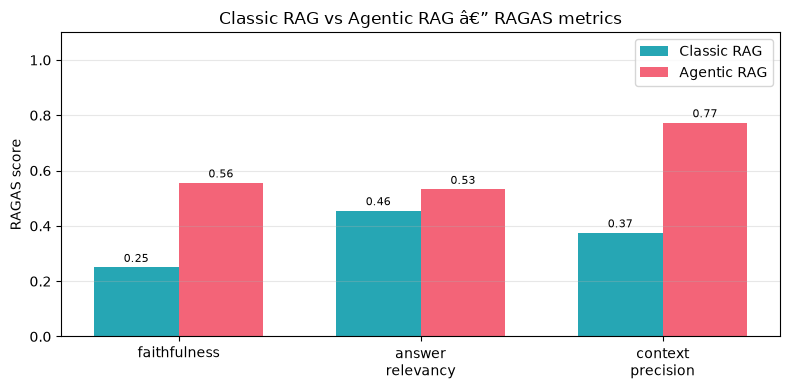

Saved: ragas_comparison.png


In [24]:
import matplotlib.pyplot as plt
import numpy as np

x     = np.arange(len(metric_cols))
width = 0.35

classic_means = [classic_df[m].mean() for m in metric_cols]
agentic_means = [agentic_df[m].mean() for m in metric_cols]

fig, ax = plt.subplots(figsize=(8, 4))
bars_c = ax.bar(x - width/2, classic_means, width, label="Classic RAG",
                color="#0097A7", alpha=0.85)
bars_a = ax.bar(x + width/2, agentic_means, width, label="Agentic RAG",
                color="#F24960", alpha=0.85)

ax.set_ylabel("RAGAS score")
ax.set_title("Classic RAG vs Agentic RAG â€” RAGAS metrics")
ax.set_xticks(x)
ax.set_xticklabels([m.replace("_", "\n") for m in metric_cols])
ax.set_ylim(0, 1.1)
ax.legend()
ax.bar_label(bars_c, fmt="%.2f", padding=2, fontsize=8)
ax.bar_label(bars_a, fmt="%.2f", padding=2, fontsize=8)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("ragas_comparison.png", dpi=150)
plt.show()
print("Saved: ragas_comparison.png")

### 5.3 When to use which approach?

| | Classic RAG | Agentic RAG |
|---|---|---|
| **Retrieval** | Fixed: always k chunks, one shot | Flexible: the LLM decides when and what to retrieve |
| **Multi-step** | No â€” one retrieval per question | Yes â€” can retrieve multiple times with refined queries |
| **Latency** | Lower â€” one LLM call | Higher â€” multiple LLM calls |
| **Faithfulness** | Bounded by quality of first retrieval | Can improve by re-querying |
| **Complexity** | Simple chain | Requires a loop + tool binding |
| **Best for** | Simple factual questions | Complex questions requiring synthesis |

### 5.4 âœï¸ Exercise â€” Identify failure cases

Find one question where **Classic RAG fails** but **Agentic RAG succeeds** (or vice versa).  
Explain why by looking at the RAGAS per-question scores and the retrieved chunks.

In [25]:
# ── Step 1: find the questions with the largest gap between the two approaches ──
import pandas as pd

metric_cols = ["faithfulness", "answer_relevancy", "context_precision"]

# Per-question gap: positive = Agentic RAG scored higher, negative = Classic RAG did.
gap_df = pd.DataFrame({"question": EVAL_QUESTIONS})
for col in metric_cols:
    gap_df[f"Δ {col}"] = agentic_df[col].values - classic_df[col].values
gap_df["Δ mean"] = gap_df[[f"Δ {col}" for col in metric_cols]].mean(axis=1)

print("Score gap per question (Agentic − Classic), sorted by mean gap:")
print(gap_df.sort_values("Δ mean", ascending=False).round(2).to_string())

# Q2 and Q5: the classic RAG scored 0 on all three metrics, the agentic one did not.
CASE_INDICES = [1, 4]
print("\nSelected cases:")
for idx in CASE_INDICES:
    print(f"  Q{idx + 1}: {EVAL_QUESTIONS[idx]}  (Δ mean = {gap_df.loc[idx, 'Δ mean']:+.2f})")

Score gap per question (Agentic − Classic), sorted by mean gap:
                                                          question  Δ faithfulness  Δ answer_relevancy  Δ context_precision  Δ mean
1                                     Which models were evaluated?            0.67                0.82                 0.33    0.61
4            What was the main limitation faced in the experiment?            0.00                0.75                 1.00    0.58
5                      What is the future work cited in the paper?            1.00                0.00                 0.50    0.50
0                   What was the main objective of the experiment?            0.00               -0.03                 0.17    0.05
2  From which brazilian entrance exams were the questions sourced?            0.00               -0.13                -0.00   -0.04
3         What was the accuracy of the best SLM model, on average?            0.17               -0.95                 0.39   -0.13

Selected ca

In [26]:
# ── Step 2: compare the two answers and their scores ────────────────────────
def print_scores(label: str, df: pd.DataFrame, idx: int) -> None:
    """Print the three RAGAS scores of one question for one approach.

    Args:
        label: Name of the approach shown in the header (e.g. "CLASSIC RAG").
        df: RAGAS results DataFrame (``classic_df`` or ``agentic_df``).
        idx: Row index of the question in ``EVAL_QUESTIONS``.
    """
    scores = " | ".join(f"{col}={df.loc[idx, col]:.2f}" for col in metric_cols)
    print(f"\n▶ {label}  [{scores}]")


for idx in CASE_INDICES:
    print("═" * 72)
    print(f"Q{idx + 1}: {EVAL_QUESTIONS[idx]}")
    print("═" * 72)
    print_scores("CLASSIC RAG", classic_df, idx)
    print(textwrap.fill(classic_answers[idx], width=72))
    print_scores("AGENTIC RAG", agentic_df, idx)
    print(textwrap.fill(agentic_answers[idx], width=72))
    print()

════════════════════════════════════════════════════════════════════════
Q2: Which models were evaluated?
════════════════════════════════════════════════════════════════════════

▶ CLASSIC RAG  [faithfulness=0.00 | answer_relevancy=0.00 | context_precision=0.00]
I don't know — the document does not mention this.

▶ AGENTIC RAG  [faithfulness=0.67 | answer_relevancy=0.82 | context_precision=0.33]
Based on the information provided, the models evaluated in this study
include:  1. Small Language Models (SLMs) 2. Language Models (LLMs) 3.
Language Models (LLMs) evaluated by Holistic evaluation 4. Language
Models (LLMs) evaluated by ENEM-Challenge (2009 exam) 5. Early GPT
models  These models were evaluated in the context of educational
evaluation, specifically for Brazilian university entrance exams and the
ENEM (Exame Nacional do Ensino Médio).

════════════════════════════════════════════════════════════════════════
Q5: What was the main limitation faced in the experiment?
══════════════

In [27]:
# ── Step 3a: the chunks that RAGAS used to score BOTH approaches ─────────────
for idx in CASE_INDICES:
    same = classic_contexts[idx] == agentic_contexts[idx]
    print("═" * 72)
    print(f"Q{idx + 1}: {EVAL_QUESTIONS[idx]}")
    print(f"Classic and agentic were scored on the SAME chunks? {same}")
    print("═" * 72)
    for rank, chunk in enumerate(classic_contexts[idx], start=1):
        print(f"\n[Chunk {rank}] {len(chunk)} chars")
        print(textwrap.fill(chunk[:350], width=72))
    print()

════════════════════════════════════════════════════════════════════════
Q2: Which models were evaluated?
Classic and agentic were scored on the SAME chunks? True
════════════════════════════════════════════════════════════════════════

[Chunk 1] 478 chars
shot evaluation of 12 models on multidisciplinary questions. Our results
show that compact models are much cheaper than larger LLMs, but their
performance generally remains uneven across subjects and visual-context
demands. These findings highlight both the promise and the current
limits of SLMs for scalable educational evaluation in Brazilian Port

[Chunk 2] 467 chars
of the 62nd Annual Meeting of the Association for Computational
Linguistics, pages 7768–7791. FUVEST (2026). Fundação universitária para
o vestibular. Accessed: 2026-02-10. Godoy, H. (2025). Alvorada-bench:
Can language models solve brazilian university en- trance exams?arXiv
preprint arXiv:2508.15835. INEP (2026). Exame nacional do ensino médio
(e

[Chunk 3] 489 chars

In [28]:
# ── Step 3b: the chunks the agent ACTUALLY read ────────────────────────────
# `agentic_contexts` comes from `retriever.invoke(question)`, i.e. a search with
# the ORIGINAL question. But the agent writes its own query when it calls the
# `retrieve` tool, so it may have read different chunks. We re-run the agent
# with the same loop as `agentic_rag`, this time recording every tool call.

def agentic_rag_traced(
    question: str, max_steps: int = 6
) -> tuple[str, list[tuple[str, list[Document]]]]:
    """Run the Agentic RAG loop and record every retrieval the agent performs.

    Same logic as ``agentic_rag`` (same system prompt, same tool, one tool call
    per step), but it also stores the query written by the agent and the
    chunks returned for it.

    Args:
        question: The user question.
        max_steps: Maximum number of LLM calls before giving up.

    Returns:
        A tuple ``(answer, retrievals)`` where ``retrievals`` is a list of
        ``(query, documents)`` pairs, one per tool call, in call order.
    """
    messages = [SystemMessage(AGENTIC_SYSTEM), HumanMessage(question)]
    retrievals: list[tuple[str, list[Document]]] = []

    for _ in range(max_steps):
        response = agentic_llm.invoke(messages)
        messages.append(response)
        if not response.tool_calls:
            return response.content, retrievals

        tool_call = response.tool_calls[0]
        query = tool_call["args"]["query"]
        # Same search the `retrieve` tool performs internally (k=4).
        docs = vectorstore.as_retriever(search_kwargs={"k": 4}).invoke(query)
        retrievals.append((query, docs))
        messages.append(
            ToolMessage(content=retrieve.invoke(query), tool_call_id=tool_call["id"])
        )

    return "[max steps reached without final answer]", retrievals


for idx in CASE_INDICES:
    question = EVAL_QUESTIONS[idx]
    answer, retrievals = agentic_rag_traced(question)
    evaluated = set(agentic_contexts[idx])

    print("═" * 72)
    print(f"Q{idx + 1}: {question}")
    print(f"Agent made {len(retrievals)} retrieve call(s)")
    print("═" * 72)
    for call, (query, docs) in enumerate(retrievals, start=1):
        print(f"\n  Call {call} — query written by the agent: {query!r}")
        for rank, doc in enumerate(docs, start=1):
            flag = "same as evaluated" if doc.page_content in evaluated else "NOT in evaluated contexts"
            snippet = doc.page_content[:90].replace("\n", " ")
            print(f"    [{rank}] page={doc.metadata.get('page', '?')} ({flag}) {snippet}...")
    print(f"\n  Re-run answer identical to the evaluated one? {answer == agentic_answers[idx]}")
    print()

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


════════════════════════════════════════════════════════════════════════
Q2: Which models were evaluated?
Agent made 1 retrieve call(s)
════════════════════════════════════════════════════════════════════════

  Call 1 — query written by the agent: 'Which models were evaluated?'
    [1] page=0 (same as evaluated) shot evaluation of 12 models on multidisciplinary questions. Our results show that compact...
    [2] page=10 (same as evaluated) of the 62nd Annual Meeting of the Association for Computational Linguistics, pages 7768–77...
    [3] page=11 (same as evaluated) (BRACIS), pages 426–431. IEEE. A. Prompts This appendix provides the exact prompts used to...
    [4] page=1 (same as evaluated) models not only by answer accuracy but also by their practical deployment cost. A second r...

  Re-run answer identical to the evaluated one? True



Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


════════════════════════════════════════════════════════════════════════
Q5: What was the main limitation faced in the experiment?
Agent made 1 retrieve call(s)
════════════════════════════════════════════════════════════════════════

  Call 1 — query written by the agent: 'main limitation experiment'
    [1] page=1 (NOT in evaluated contexts) system. We rely on a dataset comprising questions from ENEM, FUVEST (USP), and Unicamp, re...
    [2] page=2 (same as evaluated) predicted_answer(the selected letter or value, constrained against the dynamically parsed ...
    [3] page=0 (same as evaluated) shot evaluation of 12 models on multidisciplinary questions. Our results show that compact...
    [4] page=11 (NOT in evaluated contexts) (BRACIS), pages 426–431. IEEE. A. Prompts This appendix provides the exact prompts used to...

  Re-run answer identical to the evaluated one? True



Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### Step 4 — Explanation of the failure cases

**Q2 — "Which models were evaluated?"** RAGAS says the classic RAG failed (0 / 0 / 0) and the agentic RAG succeeded, but it is the opposite. Both approaches received exactly the same 4 chunks (abstract, references, prompt appendix and related work): they say *"12 models"* but never name them, because the model names only appear in the tables, which `PyPDFLoader` turned into unreadable chunks. The classic RAG correctly said *"I don't know"*, while the agent built a list of categories (*"Early GPT models"*, *"LLMs evaluated by ENEM-Challenge"*) from the related-work and reference chunks, which is a hallucination that still got faithfulness 0.67 and answer relevancy 0.82.

**Q5 — "What was the main limitation faced in the experiment?"** Here the classic RAG did have the right chunk (chunk 2, from the paper's limitations paragraph: third-party API non-determinism and the zero-shot setting), but the 3B model did not connect it to the word *"limitation"* and answered *"I don't know"*. The agent rewrote the query as `'main limitation experiment'`, lost that chunk (Step 3b) and answered with a generic limitation inferred from the abstract (*"uneven performance across subjects"*). RAGAS rewarded it with context precision 1.0, even though the answer is not the limitation the paper states.

**Takeaway.** On these two questions the agentic RAG did not win by retrieving better. It won because its prompt never allows a refusal, while the classic prompt does, and RAGAS without a reference gives 0 to any *"I don't know"* (noncommittal → relevancy 0, no statements → faithfulness 0, no chunk "useful" → precision 0). Three changes would make the comparison trustworthy:
1. Give both approaches the same refusal rule.
2. Score the agent on the chunks it actually read (Step 3b).
3. Add `reference` answers so that correctness and context recall can be measured.

---
## Checkpoint â€” What you have built

```
  ChromaDB (from Part 1)
       â”‚
       â”œâ”€â”€â–º Classic RAG chain (LCEL)              âœ…
       â”‚         â”‚
       â”‚         â–¼
       â”‚    answer (one-shot retrieval)
       â”‚
       â”œâ”€â”€â–º Hybrid retriever (BM25 + vector)       âœ…
       â”‚         â”‚
       â”‚         â–¼
       â”‚    better keyword recall
       â”‚
       â””â”€â”€â–º Agentic RAG (retrieve as @tool)        âœ…
                 â”‚
                 â–¼
            multi-step reasoning loop
                 â”‚
                 â–¼
            RAGAS evaluation                       âœ…
            (faithfulness Â· context precision Â· answer relevancy)
```

### In TP3 (CrewAI) you will add:

```
  Agentic RAG tool
       â”‚
       â–¼
  CrewAI multi-agent system
  (Researcher agent + Writer agent + Reviewer agent)
       â”‚
       â–¼
  Structured report generated collaboratively
```